In [1]:
import numpy as np 
import pandas as pd 
import plotly.express  as px

In [2]:
df=pd.read_csv("flights.csv")
df.head(2)

,DayofMonth,DayOfWeek,Carrier,OriginAirportID,DestAirportID,DepDelay,ArrDelay
0,19,5,DL,11433,13303,-3,1
1,19,5,DL,14869,12478,0,-8


### data undertanding 

### data column description


In [3]:

# التقريب لاقرب رقمين  عشريتين فقط
pd.set_option('display.float_format', lambda x: '%.2f' % x)

df.describe()

,DayofMonth,DayOfWeek,OriginAirportID,DestAirportID,DepDelay,ArrDelay
count,2702218.00,2702218.00,2702218.00,2702218.00,2702218.00,2702218.00
mean,15.80,3.90,12742.60,12743.00,10.51,6.66
std,8.80,1.99,1501.84,1501.80,36.03,38.55
min,1.00,1.00,10140.00,10140.00,-63.00,-94.00
25%,8.00,2.00,11292.00,11292.00,-4.00,-11.00
50%,16.00,4.00,12892.00,12892.00,-1.00,-3.00
75%,23.00,6.00,14057.00,14057.00,9.00,10.00
max,31.00,7.00,15376.00,15376.00,1863.00,1845.00


In [4]:
df.columns

Index(['DayofMonth', 'DayOfWeek', 'Carrier', 'OriginAirportID',
       'DestAirportID', 'DepDelay', 'ArrDelay'],
      dtype='object')

In [5]:

px.histogram(df, x= 'DepDelay', title= 'DepDelay').show()
px.box( df, x='DepDelay', title= 'DepDelay',points=False).show()

In [6]:

px.histogram(df, x= 'ArrDelay', title= 'ArrDelay').show()
px.box( df, x='ArrDelay', title= 'ArrDelay',points=False).show()

In [7]:
df.columns

Index(['DayofMonth', 'DayOfWeek', 'Carrier', 'OriginAirportID',
       'DestAirportID', 'DepDelay', 'ArrDelay'],
      dtype='object')

In [8]:
df1=pd.read_csv("column description.csv")
#علشان يظهر كل الكلام نكتب الكود الجاي دا 
pd.set_option('display.max_colwidth', None)

df1

,اسم العمود,المعنى والوصف
0,DayofMonth,رقم اليوم في الشهر: رقم يُعبر عن يوم مغادرة الرحلة خلال الشهر (من 1 إلى 31).
1,DayOfWeek,رقم اليوم في الأسبوع: يُحدد اليوم الذي تمت فيه الرحلة (مثلاً: 1 يعني الاثنين، 7 يعني الأحد).
2,Carrier,شركة الطيران: كود أو رمز يمثل شركة الطيران المسؤولة عن الرحلة (مثل AA لـ American Airlines).
3,OriginAirportID,معرف مطار المغادرة: رقم تعريفي فريد (ID) للمطار الذي أقلعت منه الطائرة.
4,DestAirportID,معرف مطار الوصول: رقم تعريفي فريد (ID) للمطار الذي ستهبط فيه الطائرة (Destination).
5,DepDelay,تأخير المغادرة (Departure Delay): فرق الوقت بالدقائق بين موعد الإقلاع المجدول والإقلاع الفعلي. (الرقم الموجب يعني تأخير، والمنافي يعني إقلاع مبكر).
6,ArrDelay,تأخير الوصول (Arrival Delay): فرق الوقت بالدقائق بين موعد الوصول المجدول والوصول الفعلي. (الرقم الموجب يعني تأخير، والمنافي يعني وصول مبكر).


### to know data types for each column 


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2702218 entries, 0 to 2702217
Data columns (total 7 columns):
 #   Column           Dtype 
---  ------           ----- 
 0   DayofMonth       int64 
 1   DayOfWeek        int64 
 2   Carrier          object
 3   OriginAirportID  int64 
 4   DestAirportID    int64 
 5   DepDelay         int64 
 6   ArrDelay         int64 
dtypes: int64(6), object(1)
memory usage: 144.3+ MB


### knowing no.of rows and columns 

In [10]:
df.shape

(2702218, 7)

In [11]:
summary_df = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.values,
    'Non-Null Count': df.notnull().sum().values,
    'Missing Values': df.isnull().sum().values,
    'Unique Values': df.nunique().values
})

summary_df

,Column Name,Data Type,Non-Null Count,Missing Values,Unique Values
0,DayofMonth,int64,2702218,0,31
1,DayOfWeek,int64,2702218,0,7
2,Carrier,object,2702218,0,16
3,OriginAirportID,int64,2702218,0,70
4,DestAirportID,int64,2702218,0,70
5,DepDelay,int64,2702218,0,945
6,ArrDelay,int64,2702218,0,979


### 70 airport and 16 flight company  and no missing values in data 

In [12]:
#for check dublicate
# حساب إجمالي عدد الصفوف المكررة
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

# عرض الصفوف المكررة نفسها لإلقاء نظرة عليها
if duplicate_count > 0:
    print(df[df.duplicated()])

Total duplicate rows: 5561
         DayofMonth  DayOfWeek Carrier  OriginAirportID  DestAirportID  \
22944            16          2      EV            12191          11298   
23665            12          5      EV            10792          11618   
23928            17          3      EV            13930          11042   
24413            18          4      EV            11042          13930   
24551            18          4      EV            11042          13930   
...             ...        ...     ...              ...            ...   
2599977          17          4      9E            13871          13487   
2601601          29          2      9E            12478          13930   
2602444          29          2      9E            13930          12478   
2618706           7          1      AA            12953          13930   
2618912           7          1      AA            13930          12953   

         DepDelay  ArrDelay  
22944           0         0  
23665           0       

In [13]:
# to know dublicated data based on ('DestAirportID', 'OriginAirportID' )
duplicate_rows = df[df.duplicated(subset=['DestAirportID', 'OriginAirportID'], keep=False)]

# عرض النتيجة
duplicate_rows

,DayofMonth,DayOfWeek,Carrier,OriginAirportID,DestAirportID,DepDelay,ArrDelay
0,19,5,DL,11433,13303,-3,1
1,19,5,DL,14869,12478,0,-8
2,19,5,DL,14057,14869,-4,-15
3,19,5,DL,15016,11433,28,24
4,19,5,DL,11193,12892,-6,-11
...,...,...,...,...,...,...,...
2702213,19,6,DL,13204,14869,1,-3
2702214,19,6,DL,10397,13495,-2,-3
2702215,19,6,DL,10140,10397,18,9
2702216,19,6,DL,10397,13244,10,7


In [14]:
#checking for any problem in data input 
for col in df.columns:

    print(col)
    print(df[col].nunique())
    print(df[col].unique())
    print('-' * 100)

DayofMonth
31
[19 20 18 16 17 21 22 23 24 25 26 28 29 30  2  3  4  5  7  8  9 10 11 12
 14 15  1  6 13 27 31]
----------------------------------------------------------------------------------------------------
DayOfWeek
7
[5 6 4 2 3 7 1]
----------------------------------------------------------------------------------------------------
Carrier
16
['DL' 'AA' 'EV' 'B6' 'F9' 'FL' 'HA' 'MQ' '9E' 'AS' 'US' 'UA' 'VX' 'WN'
 'YV' 'OO']
----------------------------------------------------------------------------------------------------
OriginAirportID
70
[11433 14869 14057 15016 11193 10397 11278 14107 11298 12451 12953 13204
 13487 12889 14027 13244 14747 10423 11292 12892 13198 11057 14100 12478
 11697 12339 12266 15304 14635 13930 14679 10721 10821 11066 13495 10140
 10792 14492 11618 14771 12173 14908 13342 14730 14122 10693 13303 14893
 14524 14843 15376 13232 14683 13871 11042 14570 12264 13830 13931 10299
 14307 10529 14831 12191 13796 13851 12954 11259 10800 13891]
-------------------

In [15]:
# adding a new column to data called day name 
day_map = {1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat', 7: 'Sun'}
df['Day_Name'] = df['DayOfWeek'].map(day_map)
df.head(2)

,DayofMonth,DayOfWeek,Carrier,OriginAirportID,DestAirportID,DepDelay,ArrDelay,Day_Name
0,19,5,DL,11433,13303,-3,1,Fri
1,19,5,DL,14869,12478,0,-8,Fri


In [16]:
# إعادة ترتيب الأعمدة حسب الترتيب الجديد المطلوب
new_order = ['Day_Name', 'DayOfWeek', 'DayofMonth', 'Carrier', 'OriginAirportID', 'DestAirportID', 'DepDelay', 'ArrDelay']

# تطبيق الترتيب الجديد على الجدول
df = df[new_order]

# التأكد من الترتيب
df.head()

,Day_Name,DayOfWeek,DayofMonth,Carrier,OriginAirportID,DestAirportID,DepDelay,ArrDelay
0,Fri,5,19,DL,11433,13303,-3,1
1,Fri,5,19,DL,14869,12478,0,-8
2,Fri,5,19,DL,14057,14869,-4,-15
3,Fri,5,19,DL,15016,11433,28,24
4,Fri,5,19,DL,11193,12892,-6,-11


In [17]:
# حساب متوسط تأخير المغادرة والوصول
avg_dep_delay = df['DepDelay'].mean()
avg_arr_delay = df['ArrDelay'].mean()

print(f"متوسط تأخير المغادرة: {avg_dep_delay:.2f} دقيقة")
print(f"متوسط تأخير الوصول: {avg_arr_delay:.2f} دقيقة")

متوسط تأخير المغادرة: 10.51 دقيقة
متوسط تأخير الوصول: 6.66 دقيقة


In [18]:
# حساب الفرق بين تأخير الإقلاع وتأخير الوصول
# (الرقم الموجب يعني أن الرحلة سرّعت وعوّضت وقتاً)
df['Time_Recovered'] = df['DepDelay'] - df['ArrDelay']

# متوسط الدقائق الموفرة
print(f"متوسط الدقائق المعوضة أثناء الطيران: {df['Time_Recovered'].mean():.2f} دقيقة")

متوسط الدقائق المعوضة أثناء الطيران: 3.86 دقيقة


In [19]:


# حساب نسبة الرحلات المتأخرة والمضبوطة في المغادرة
dep_delayed_pct = (df['DepDelay'] > 0).mean() * 100
dep_ontime_pct = (df['DepDelay'] <= 0).mean() * 100

# حساب نسبة الرحلات المتأخرة والمضبوطة في الوصول
arr_delayed_pct = (df['ArrDelay'] > 0).mean() * 100
arr_ontime_pct = (df['ArrDelay'] <= 0).mean() * 100

print(f"المغادرة في الموعد/مبكرة: {dep_ontime_pct:.1f}% | متأخرة: {dep_delayed_pct:.1f}%")
print(f"الوصول في الموعد/مبكر:  {arr_ontime_pct:.1f}% | متأخر: {arr_delayed_pct:.1f}%")

المغادرة في الموعد/مبكرة: 58.4% | متأخرة: 41.6%
الوصول في الموعد/مبكر:  59.1% | متأخر: 40.9%


In [20]:
# حساب نسبة التأخير عند الوصول لكل شركة طيران مرتبة من الأفضل للأفضل
carrier_performance = df.groupby('Carrier').agg(
    total_flights=('ArrDelay', 'count'),
    delayed_flights=('ArrDelay', lambda x: (x > 0).sum()),
    avg_arr_delay=('ArrDelay', 'mean')
).reset_index()

carrier_performance['delay_rate_%'] = (carrier_performance['delayed_flights'] / carrier_performance['total_flights']) * 100

# ترتيب الشركات من الأقل تأخيراً للأكثر تأخيراً
carrier_performance.sort_values(by='delay_rate_%')

,Carrier,total_flights,delayed_flights,avg_arr_delay,delay_rate_%
0,9E,80031,26378,4.79,32.96
4,DL,381657,127456,2.80,33.40
8,HA,17432,6320,1.53,36.26
11,UA,286418,105990,5.16,37.01
2,AS,68555,25865,-0.27,37.73
5,EV,157928,62185,10.21,39.38
12,US,233321,92498,3.92,39.64
10,OO,160164,63744,6.34,39.80
13,VX,34739,13928,9.66,40.09
1,AA,289855,116679,7.14,40.25


In [21]:
import plotly.express as px

# 1. حساب معامل الارتباط على كل البيانات
corr_value = df['DepDelay'].corr(df['ArrDelay'])
print(f"معامل الارتباط (Correlation): {corr_value:.2f}")

# 2. أخذ عينة للرسم لتفادي بطء الشاشة
df_sample = df.sample(n=min(10000, len(df)), random_state=42)

# 3. الرسم البياني
fig = px.scatter(
    df_sample, 
    x='DepDelay', 
    y='ArrDelay',
    hover_data=['Carrier'],
    trendline='ols',
    opacity=0.3,
    title=f'العلاقة بين تأخير المغادرة والوصول (معامل الارتباط: {corr_value:.2f})',
    labels={'DepDelay': 'تأخير المغادرة (دقيقة)', 'ArrDelay': 'تأخير الوصول (دقيقة)'}
)

fig.show()

معامل الارتباط (Correlation): 0.94


In [22]:
import pandas as pd
import plotly.express as px

# 1. تجميع البيانات وحساب النسبة
origin_performance = df.groupby('OriginAirportID').agg(
    total_flights=('DepDelay', 'count'),
    delayed_flights=('DepDelay', lambda x: (x > 0).sum()),
    avg_dep_delay=('DepDelay', 'mean')
).reset_index()

origin_performance['delay_rate_%'] = (origin_performance['delayed_flights'] / origin_performance['total_flights']) * 100

# تصفية المطارات وأخذ أسوأ 10 مطارات
top_airports = origin_performance[origin_performance['total_flights'] > 500]
worst_10_airports = top_airports.sort_values(by='avg_dep_delay', ascending=False).head(10).copy()

worst_10_airports['OriginAirportID'] = worst_10_airports['OriginAirportID'].astype(str)

# 2. الرسم مع إظهار النسبة المئوية على العمود
fig = px.bar(
    worst_10_airports,
    x='OriginAirportID',
    y='avg_dep_delay',
    text='delay_rate_%', # إظهار عمود النسبة كنص
    color='delay_rate_%',
    hover_data=['total_flights'],
    title='أسوأ 10 مطارات مغادرة من حيث متوسط وقت التأخير ونسبة التأخير',
    labels={
        'OriginAirportID': 'معرف مطار المغادرة',
        'avg_dep_delay': 'متوسط التأخير (دقيقة)',
        'delay_rate_%': 'نسبة التأخير (%)'
    },
    color_continuous_scale='Reds'
)

# 3. تنسيق النص ليظهر برقمين عشريين وعلامة % فوق الأعمدة
fig.update_traces(
    texttemplate='%{text:.1f}%', # تنسيق الرقم ليظهر بفاصلة عشرية واحدة + %
    textposition='outside'        # وضع النص فوق العمود من الخارج
)

# تعديل نطاق المحور Y ليعطي مساحة لعرض النص أعلى الأعمدة
fig.update_layout(yaxis_range=[0, worst_10_airports['avg_dep_delay'].max() * 1.15])

fig.show()

In [23]:
#•	ما هي أكثر أيام الأسبوع (DayOfWeek) ازدحاماً وتأخيراً للرحلات؟

# 1. التحليل العام: تجميع البيانات حسب يوم الأسبوع (Day_Name أو DayOfWeek)
day_summary = df.groupby(['DayOfWeek', 'Day_Name']).agg(
    total_flights=('DepDelay', 'count'),
    avg_dep_delay=('DepDelay', 'mean'),
    delayed_flights=('DepDelay', lambda x: (x > 0).sum())
).reset_index()

day_summary['delay_rate_%'] = (day_summary['delayed_flights'] / day_summary['total_flights']) * 100

# ترتيب الأيام بانتظام من الإثنين إلى الأحد
day_summary = day_summary.sort_values(by='DayOfWeek')

# 2. رسم المخطط العام تفاعلياً
fig = px.bar(
    day_summary,
    x='Day_Name',
    y='total_flights',
    color='avg_dep_delay',
    text='delay_rate_%',
    hover_data=['avg_dep_delay', 'delay_rate_%'],
    title='عدد الرحلات ومتوسط التأخير حسب أيام الأسبوع',
    labels={
        'Day_Name': 'يوم الأسبوع',
        'total_flights': 'إجمالي عدد الرحلات',
        'avg_dep_delay': 'متوسط التأخير (دقيقة)',
        'delay_rate_%': 'نسبة التأخير (%)'
    },
    color_continuous_scale='Reds'
)

fig.update_traces(
    texttemplate='نسبة التأخير: %{text:.1f}%',
    textposition='outside'
)

fig.update_layout(yaxis_range=[0, day_summary['total_flights'].max() * 1.15])
fig.show()

In [24]:
#لحساب نسبة التأخير لكل مطار علي حده 
# اختيار أكبر 5 مطارات من حيث عدد الرحلات
top_5_airports = df['OriginAirportID'].value_counts().head(5).index

df_top5 = df[df['OriginAirportID'].isin(top_5_airports)].copy()
df_top5['OriginAirportID'] = df_top5['OriginAirportID'].astype(str)

# تجميع حسب المطار واليوم
airport_day_summary = df_top5.groupby(['OriginAirportID', 'Day_Name', 'DayOfWeek'])['DepDelay'].mean().reset_index()
airport_day_summary = airport_day_summary.sort_values('DayOfWeek')

# رسم خطي يقارن أيام الأسبوع لكل مطار على حدة
fig_airports = px.line(
    airport_day_summary,
    x='Day_Name',
    y='DepDelay',
    color='OriginAirportID',
    markers=True,
    title='متوسط تأخير المغادرة عبر أيام الأسبوع في أكبر 5 مطارات',
    labels={'Day_Name': 'اليوم', 'DepDelay': 'متوسط التأخير (دقيقة)', 'OriginAirportID': 'المطار'}
)

fig_airports.show()

In [25]:
import pandas as pd
import plotly.express as px

# 1. تجميع البيانات حسب يوم الشهر (DayofMonth)
dom_summary = df.groupby('DayofMonth').agg(
    total_flights=('DepDelay', 'count'),
    avg_dep_delay=('DepDelay', 'mean'),
    delayed_flights=('DepDelay', lambda x: (x > 0).sum())
).reset_index()

# حساب نسبة الرحلات المتأخرة
dom_summary['delay_rate_%'] = (dom_summary['delayed_flights'] / dom_summary['total_flights']) * 100

# 2. رسم مسار التأخير عبر أيام الشهر تفاعلياً
fig = px.line(
    dom_summary,
    x='DayofMonth',
    y='avg_dep_delay',
    markers=True,
    text=dom_summary['delay_rate_%'].apply(lambda x: f"{x:.1f}%"),
    hover_data=['total_flights', 'delay_rate_%'],
    title='تغير متوسط تأخير المغادرة ونسبة التأخير عبر أيام الشهر (1 - 31)',
    labels={
        'DayofMonth': 'يوم من الشهر',
        'avg_dep_delay': 'متوسط التأخير (دقيقة)',
        'delay_rate_%': 'نسبة التأخير (%)'
    }
)

# ضبط مكان النص والتنسيق
fig.update_traces(textposition='top center')
fig.update_xaxes(dtick=1)  # إظهار كل الأيام من 1 إلى 31 على المحور

fig.show()

In [26]:
import pandas as pd
import plotly.express as px

# 1. حدد رقم المطار الذي تريد تحليله
target_airport = 12892  # استبدل الرقم بأي OriginAirportID تريد تحليله

# تصفية البيانات لهذا المطار فقط
df_airport = df[df['OriginAirportID'] == target_airport]

# 2. تجميع البيانات حسب أيام الشهر للمطار المحدد
dom_airport = df_airport.groupby('DayofMonth').agg(
    total_flights=('DepDelay', 'count'),
    avg_dep_delay=('DepDelay', 'mean'),
    delayed_flights=('DepDelay', lambda x: (x > 0).sum())
).reset_index()

dom_airport['delay_rate_%'] = (dom_airport['delayed_flights'] / dom_airport['total_flights']) * 100

# 3. الرسم البياني للمطار المحدد فقط
fig = px.line(
    dom_airport,
    x='DayofMonth',
    y='avg_dep_delay',
    markers=True,
    text=dom_airport['delay_rate_%'].apply(lambda x: f"{x:.1f}%"),
    hover_data=['total_flights', 'delay_rate_%'],
    title=f'تحليل تأخيرات أيام الشهر للمطار رقم: {target_airport}',
    labels={
        'DayofMonth': 'يوم من الشهر',
        'avg_dep_delay': 'متوسط التأخير (دقيقة)',
        'delay_rate_%': 'نسبة التأخير (%)'
    }
)

fig.update_traces(textposition='top center')
fig.update_xaxes(dtick=1)

fig.show()

In [27]:
import ipywidgets as widgets
from ipywidgets import interact

# استخراج قائمة المطارات الكبرى لتسهيل الاختيار
top_airports = df['OriginAirportID'].value_counts().head(15).index.tolist()

@interact(airport_id=top_airports)
def plot_airport_monthly_trend(airport_id):
    df_filtered = df[df['OriginAirportID'] == airport_id]
    
    summary = df_filtered.groupby('DayofMonth').agg(
        total_flights=('DepDelay', 'count'),
        avg_dep_delay=('DepDelay', 'mean'),
        delayed_flights=('DepDelay', lambda x: (x > 0).sum())
    ).reset_index()
    
    summary['delay_rate_%'] = (summary['delayed_flights'] / summary['total_flights']) * 100
    
    fig = px.line(
        summary,
        x='DayofMonth',
        y='avg_dep_delay',
        markers=True,
        title=f'تحليل حركة والتأخيرات للمطار {airport_id}',
        labels={'DayofMonth': 'يوم الشهر', 'avg_dep_delay': 'متوسط التأخير (دقيقة)'}
    )
    fig.update_xaxes(dtick=1)
    fig.show()

interactive(children=(Dropdown(description='airport_id', options=(10397, 13930, 12892, 11298, 11292, 14107, 14…

In [28]:
# اطول فتره تاخير قامت بها شركات الطيران وكانت في اي مطار 

In [29]:
import pandas as pd

# 1. التجميع للوصول لأكبر قيمة تأخير في المغادرة لكل شركة
# واستخراج الصف بالكامل لمعرفة المطار الأصلي والمراد الوصول إليه
idx_max_dep = df.groupby('Carrier')['DepDelay'].idxmax()

# 2. تصفية الجدول لعرض التفاصيل المطلوبة فقط
longest_delays = df.loc[idx_max_dep, ['Carrier', 'DepDelay', 'OriginAirportID', 'DestAirportID', 'Day_Name', 'DayofMonth']]

# 3. إعادة الترتيب من الأطول للأقصر
longest_delays = longest_delays.sort_values(by='DepDelay', ascending=False).reset_index(drop=True)

# عرض النتيجة
longest_delays.rename(columns={
    'Carrier': 'شركة الطيران',
    'DepDelay': 'أطول تأخير (بالدقائق)',
    'OriginAirportID': 'مطار المغادرة',
    'DestAirportID': 'مطار الوصول',
    'Day_Name': 'اليوم',
    'DayofMonth': 'يوم الشهر'
})

,شركة الطيران,أطول تأخير (بالدقائق),مطار المغادرة,مطار الوصول,اليوم,يوم الشهر
0,AA,1863,14107,13930,Tue,15
1,HA,1847,12889,12173,Fri,12
2,MQ,1244,14122,13930,Tue,25
3,DL,1165,10721,10397,Fri,6
4,FL,1113,12191,10397,Sun,5
5,US,860,13204,14100,Thu,18
6,EV,838,10140,12266,Mon,1
7,F9,789,13204,11292,Sun,28
8,UA,787,14122,13930,Mon,8
9,OO,773,10693,14869,Tue,24


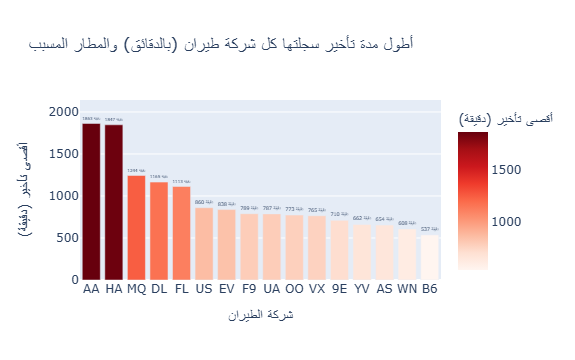

In [30]:
import plotly.express as px

fig = px.bar(
    longest_delays,
    x='Carrier',
    y='DepDelay',
    text='DepDelay',
    hover_data=['OriginAirportID', 'DestAirportID', 'Day_Name'],
    title='أطول مدة تأخير سجلتها كل شركة طيران (بالدقائق) والمطار المسبب',
    labels={
        'Carrier': 'شركة الطيران',
        'DepDelay': 'أقصى تأخير (دقيقة)',
        'OriginAirportID': 'من مطار'
    },
    color='DepDelay',
    color_continuous_scale='Reds'
)

fig.update_traces(
    texttemplate='%{text} دقيقة',
    textposition='outside'
)

fig.update_layout(yaxis_range=[0, longest_delays['DepDelay'].max() * 1.15])
fig.show()

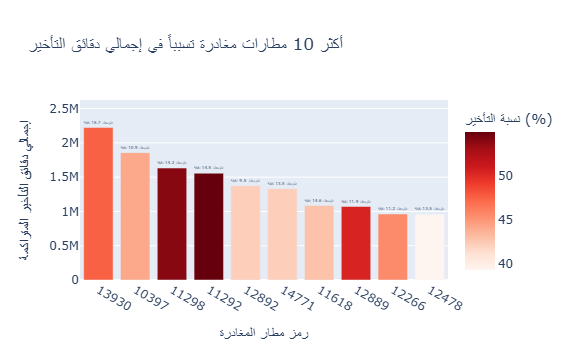

In [31]:
import pandas as pd
import plotly.express as px

# 1. حساب إجمالي ومتوسط التأخير ونسبة التأخير لكل مطار مغادرة
airport_delays = df.groupby('OriginAirportID').agg(
    total_flights=('DepDelay', 'count'),
    total_delay_minutes=('DepDelay', lambda x: x[x > 0].sum()),  # مجموع دقائق التأخير الفردية
    avg_dep_delay=('DepDelay', 'mean'),
    delayed_flights=('DepDelay', lambda x: (x > 0).sum())
).reset_index()

# حساب نسبة التأخير
airport_delays['delay_rate_%'] = (airport_delays['delayed_flights'] / airport_delays['total_flights']) * 100

# تصفية المطارات ذات الحركة المرتفعة (أكثر من 500 رحلة) وتحديد أعلى 10 مطارات تسبباً في التراكم الزمني
top_delay_airports = airport_delays[airport_delays['total_flights'] > 500].sort_values(by='total_delay_minutes', ascending=False).head(10).copy()

top_delay_airports['OriginAirportID'] = top_delay_airports['OriginAirportID'].astype(str)

# 2. رسم الملاحظات تفاعلياً بـ Plotly
fig = px.bar(
    top_delay_airports,
    x='OriginAirportID',
    y='total_delay_minutes',
    text='avg_dep_delay',
    color='delay_rate_%',
    hover_data=['total_flights', 'delay_rate_%', 'avg_dep_delay'],
    title='أكثر 10 مطارات مغادرة تسبباً في إجمالي دقائق التأخير',
    labels={
        'OriginAirportID': 'رمز مطار المغادرة',
        'total_delay_minutes': 'إجمالي دقائق التأخير المتراكمة',
        'avg_dep_delay': 'متوسط التأخير/رحلة (دقيقة)',
        'delay_rate_%': 'نسبة التأخير (%)'
    },
    color_continuous_scale='Reds'
)

fig.update_traces(
    texttemplate='متوسط: %{text:.1f} دقيقة',
    textposition='outside'
)

fig.update_layout(yaxis_range=[0, top_delay_airports['total_delay_minutes'].max() * 1.18])
fig.show()

In [32]:
df.to_csv("cleaned_df.csv" ,index= False)

In [36]:
df.columns

Index(['DayofMonth', 'DayOfWeek', 'Carrier', 'OriginAirportID',
       'DestAirportID', 'DepDelay', 'ArrDelay'],
      dtype='object')

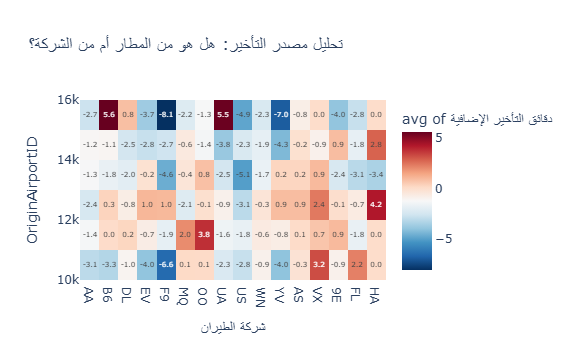

In [40]:
import pandas as pd
import plotly.express as px

# 1. قراءة البيانات (غير اسم الملف لملفك)
df = pd.read_csv('flights.csv')

# ---------------------------------------------------------
# الخطوة (أ): حساب متوسط تأخير كل شركة على مستوى كل المطارات
# ---------------------------------------------------------
# بنعرف "المعدل الطبيعي" لكل شركة
carrier_avg = df.groupby('Carrier')['DepDelay'].mean().reset_index()
carrier_avg.rename(columns={'DepDelay': 'Carrier_Normal_Delay'}, inplace=True)

# ---------------------------------------------------------
# الخطوة (ب): حساب متوسط تأخير كل شركة داخل كل مطار لوحده
# ---------------------------------------------------------
airport_carrier_avg = df.groupby(['OriginAirportID', 'Carrier'])['DepDelay'].mean().reset_index()

# ---------------------------------------------------------
# الخطوة (ج): دمج الجداول ومقارنة الأداء
# ---------------------------------------------------------
# بنحط المعدل الطبيعي للشركة جنباً إلى جنب مع أدائها في المطار
final_df = pd.merge(airport_carrier_avg, carrier_avg, on='Carrier')

# الفرق = (أداء الشركة في المطار دا) minus (أداء الشركة الطبيعي في كل المطارات)
final_df['Delay_Difference'] = final_df['DepDelay'] - final_df['Carrier_Normal_Delay']

# ---------------------------------------------------------
# الخطوة (د): الرسم التفاعلي بـ Plotly Express
# ---------------------------------------------------------
fig = px.density_heatmap(
    final_df, 
    x='Carrier',                      # شركات الطيران على المحور الأفقي
    y='OriginAirportID',               # المطارات على المحور الرأسي
    z='Delay_Difference',             # لون الخلية يعبر عن فرق التأخير
    histfunc='avg',
    color_continuous_scale='RdBu_r',  # أحمر = تأخير زائد ، أزرق = أداء ممتاز
    text_auto='.1f',                  # إظهار الأرقام فوق الخلايا
    title='تحليل مصدر التأخير: هل هو من المطار أم من الشركة؟',
    labels={
        'Carrier': 'شركة الطيران',
       ' OriginAirportID': 'مطار المغادرة',
        'Delay_Difference': 'دقائق التأخير الإضافية'
    }
)

# عرض الرسمة التفاعلية
fig.show()

#لقيت صف كامل أحمر (مطار معين):معناه إن كل الشركات أرقامها باللون الأحمر في المطار دا $\leftarrow$ المشكلة 100% من المطار.
لو لقيت عمود كامل أحمر (شركة معينة):معناه إن الشركة دي متأخرة باللون الأحمر في كل المطارات $\leftarrow$ المشكلة 100% من شركة الطيران.
لو لقيت مربع واحد بس أحمر:معناه إن الشركة دي بالذات عندها مشكلة تشغيلية خاصة جوه المطار دا فقط.

بهذا الكود وهذه الرسمه تبين لنا ان المشكله ليست في شركة الطيران ولا في المطارات 
وتبين انها حالات فرديه للشركات في المطارات المختلفه 
